# Q2 · 01 Preprocessing and data loading

5-class Amazon review rating. This notebook builds both input pipelines and records the numbers the report needs.

1. **Data**: `SetFit/amazon_reviews_multi_en` (train 200k / validation 5k / test 5k), with each review's title put back in front of its body.
2. **Classic pipeline** (BiGRU baseline): clean HTML and URLs, lowercase, spaCy tokens, vocabulary with a minimum frequency, GloVe 6B 300-d embedding matrix, padding / `<unk>` / max length 200.
3. **RoBERTa pipeline**: `RobertaTokenizerFast` (byte-level BPE, `<s> … </s>`), truncation to 256, `attention_mask`, dynamic padding with a data collator.

Only train and validation are loaded here. The test split is read once, in the final evaluation.

In [1]:
import os
import sys
import warnings
from pathlib import Path

warnings.filterwarnings("ignore", message="IProgress not found")   # plain-text progress bars outside Jupyter widgets

BRANCH = "main"   # the branch to clone when this notebook runs outside the repo (e.g. imported into Kaggle)

root = Path.cwd().resolve()
while not (root / "common").is_dir() and root != root.parent:
    root = root.parent
if not (root / "common").is_dir():
    import subprocess
    root = Path.cwd() / "NLP-Group-Assignment-2"
    if not root.exists():
        subprocess.run(["git", "clone", "-q", "-b", BRANCH,
                        "https://github.com/Akshats-git/NLP-Group-Assignment-2.git", str(root)], check=True)
    os.chdir(root / "Question-2")
sys.path[:0] = [str(root), str(root / "Question-2")]

LIMIT = int(os.environ.get("Q2_LIMIT", 0)) or None   # set Q2_LIMIT for a quick run on a random subset
NUM_PROC = os.cpu_count()

## 1. Data

The SetFit copy of the dataset only kept the review body. `mteb/amazon_reviews_multi` (config `en`) has the same ids and splits with `text = title + "\n\n" + body`, so the titles are taken from there by id. A title is only attached when the two bodies match. Splits and labels come from SetFit, as the brief asks.

In [2]:
import numpy as np
from q2.data import STAR_LABELS, label_counts, load_reviews

reviews = load_reviews(limit=LIMIT)
reviews

DatasetDict({
    train: Dataset({
        features: ['id', 'text', 'label', 'title', 'body', 'title_found'],
        num_rows: 200000
    })
    validation: Dataset({
        features: ['id', 'text', 'label', 'title', 'body', 'title_found'],
        num_rows: 5000
    })
})

In [3]:
for split, ds in reviews.items():
    print(f"{split:<10} {len(ds):>7,} reviews | per star {label_counts(ds)} | title attached {np.mean(ds['title_found']):.1%}")

train      200,000 reviews | per star [40000, 40000, 40000, 40000, 40000] | title attached 100.0%
validation   5,000 reviews | per star [1000, 1000, 1000, 1000, 1000] | title attached 100.0%


In [4]:
for row in reviews["train"].select(range(3)):
    print(f"[{row['label'] + 1} stars] title: {row['title']!r}")
    print(f"           body:  {row['body'][:150]!r}")
    print(f"           text:  {row['text'][:150]!r}\n")

[1 stars] title: "I'll spend twice the amount of time boxing up the whole useless thing and send it back with a 1-star review ..."
           body:  'Arrived broken. Manufacturer defect. Two of the legs of the base were not completely formed, so there was no way to insert the casters. I unpackaged t'
           text:  "I'll spend twice the amount of time boxing up the whole useless thing and send it back with a 1-star review ... Arrived broken. Manufacturer defect. T"

[1 stars] title: 'Not use able'
           body:  'the cabinet dot were all detached from backing... got me'
           text:  'Not use able. the cabinet dot were all detached from backing... got me'

[1 stars] title: 'The product is junk.'
           body:  "I received my first order of this product and it was broke so I ordered it again. The second one was broke in more places than the first. I can't blam"
           text:  'The product is junk. I received my first order of this product and it was broke so I ordered it

The classes are balanced (40k reviews per star in train), so accuracy and macro-F1 tell a similar story and class-weighted cross-entropy would change little. That is why the ablation compares mean pooling with first-token pooling instead.

## 2. Classic pipeline for the BiGRU baseline

Lowercasing matches GloVe 6B, which is uncased. Only spaCy's rule-based English tokenizer is used (`spacy.blank("en")`): no tagger or parser is needed, and it splits contractions (`don't` → `do n't`) the same way GloVe's training text was tokenised.

In [5]:
from q2 import classic

sample = 'Not worth it!! <br />Broke after 2 days, see https://example.com &amp; don\'t buy'
print(classic.clean(sample))
print(classic.tokenize([sample])[0])

not worth it!! broke after 2 days, see & don't buy
['not', 'worth', 'it', '!', '!', 'broke', 'after', '2', 'days', ',', 'see', '&', 'do', "n't", 'buy']


The brief asks for HTML and URL cleaning, so the pipeline does it. This copy of the data is already almost clean, though, which is also why the RoBERTa pipeline can take the raw text as it is:

In [6]:
import re

texts = reviews["train"]["text"]
for name, pattern in [("HTML tag", r"<[^>]+>"), ("URL", r"https?://|www\.")]:
    rx = re.compile(pattern)
    print(f"{name:<8} in {sum(bool(rx.search(t)) for t in texts):,} of {len(texts):,} training reviews")

HTML tag in 2 of 200,000 training reviews


URL      in 8 of 200,000 training reviews


In [7]:
tokenized = classic.add_tokens(reviews, num_proc=NUM_PROC)
vocab = classic.build_vocab(tokenized["train"]["tokens"], min_freq=classic.MIN_FREQ)
encoded = classic.encode(tokenized, vocab, max_len=classic.MAX_LEN)

print(f"vocabulary: {len(vocab):,} entries (min_freq={classic.MIN_FREQ}, built from train only)")
print(f"validation OOV rate: {vocab.oov_rate(tokenized['validation']['tokens']):.2%}")

spaCy tokenising (num_proc=8):   0%|          | 0/200000 [00:00<?, ? examples/s]

spaCy tokenising (num_proc=8):   0%|          | 1000/200000 [00:00<02:40, 1239.63 examples/s]

spaCy tokenising (num_proc=8):   4%|▍         | 9000/200000 [00:01<00:17, 10700.75 examples/s]

spaCy tokenising (num_proc=8):   8%|▊         | 17000/200000 [00:01<00:09, 19750.71 examples/s]

spaCy tokenising (num_proc=8):  12%|█▏        | 23000/200000 [00:01<00:06, 26175.55 examples/s]

...

encoding: 100%|██████████| 200000/200000 [00:04<00:00, 43303.00 examples/s]

encoding:   0%|          | 0/5000 [00:00<?, ? examples/s]

encoding:  80%|████████  | 4000/5000 [00:00<00:00, 31112.42 examples/s]

encoding: 100%|██████████| 5000/5000 [00:00<00:00, 33136.28 examples/s]

vocabulary: 32,878 entries (min_freq=2, built from train only)
validation OOV rate: 0.38%


In [8]:
from q2.data import length_stats

classic_lengths = {split: length_stats(ds["n_tokens"], cutoffs=(classic.MAX_LEN,)) for split, ds in encoded.items()}
classic_lengths

{'train': {'mean': 44.636595,
  'p50': 34.0,
  'p90': 89.0,
  'p95': 117.0,
  'p99': 196.0,
  'max': 914,
  'share_over_200': 0.00932},
 'validation': {'mean': 45.087,
  'p50': 34.0,
  'p90': 90.0,
  'p95': 117.0,
  'p99': 191.02000000000044,
  'max': 724,
  'share_over_200': 0.0094}}

**GloVe vectors.** `find_glove` looks for `glove.6B.300d.txt` in an attached Kaggle dataset, `$Q2_GLOVE` or `Question-2/data/glove/`, and only downloads the 822 MB Stanford zip if none is found. Words without a vector start from N(0, σ_GloVe) and `<pad>` is all zeros.

In [9]:
glove_path = classic.find_glove(classic.GLOVE_DIM)
vectors = classic.load_glove(glove_path, vocab.itos)
embeddings, coverage = classic.embedding_matrix(vocab, vectors)
print(glove_path.relative_to(root) if glove_path.is_relative_to(root) else glove_path)
print(f"embedding matrix {tuple(embeddings.shape)}")
coverage

Question-2/data/glove/glove.6B.300d.txt
embedding matrix (32878, 300)


{'vocab_size': 32878,
 'types_with_vector': 28949,
 'type_coverage': 0.8806047332238243,
 'token_coverage': 0.9970924784012201}

In [10]:
row = encoded["train"][0]
print(row["tokens"][:25])
print(row["ids"][:25])
print(vocab.decode(row["ids"][:25], skip_special=False))

batch = next(iter(classic.make_loader(encoded["train"], batch_size=4, shuffle=True, seed=42, num_workers=0)))
{k: (tuple(v.shape), v.dtype) for k, v in batch.items()}

['i', "'ll", 'spend', 'twice', 'the', 'amount', 'of', 'time', 'boxing', 'up', 'the', 'whole', 'useless', 'thing', 'and', 'send', 'it', 'back', 'with', 'a', '1', '-', 'star', 'review', '...']
[6, 389, 832, 618, 5, 624, 16, 77, 6341, 54, 5, 523, 577, 214, 8, 483, 7, 105, 24, 11, 266, 62, 190, 363, 55]
['i', "'ll", 'spend', 'twice', 'the', 'amount', 'of', 'time', 'boxing', 'up', 'the', 'whole', 'useless', 'thing', 'and', 'send', 'it', 'back', 'with', 'a', '1', '-', 'star', 'review', '...']


{'ids': ((4, 187), torch.int64),
 'ids_lengths': ((4,), torch.int64),
 'label': ((4,), torch.int64)}

## 3. RoBERTa pipeline

Byte-level BPE needs no cleaning or lowercasing: casing, punctuation and emoji all carry signal and the tokenizer never produces `<unk>`. Reviews are tokenised once without padding. `DataCollatorWithPadding` then pads each batch only to its own longest review, rounded up to a multiple of 8 for the tensor cores.

In [11]:
from q2 import roberta_data

tokenizer = roberta_data.get_tokenizer()
ids = tokenizer(sample)["input_ids"]
print(tokenizer.convert_ids_to_tokens(ids))

['<s>', 'Not', 'Ġworth', 'Ġit', '!!', 'Ġ<', 'br', 'Ġ/>', 'Bro', 'ke', 'Ġafter', 'Ġ2', 'Ġdays', ',', 'Ġsee', 'Ġhttps', '://', 'example', '.', 'com', 'Ġ&', 'amp', ';', 'Ġdon', "'t", 'Ġbuy', '</s>']


In [12]:
rob = roberta_data.tokenize(reviews, tokenizer, max_length=roberta_data.MAX_LEN, num_proc=NUM_PROC)
roberta_lengths = {split: length_stats(ds["n_tokens"], cutoffs=(128, roberta_data.MAX_LEN)) for split, ds in rob.items()}
roberta_lengths

{'train': {'mean': 48.87597,
  'p50': 38.0,
  'p90': 95.0,
  'p95': 124.0,
  'p99': 206.0,
  'max': 954,
  'share_over_128': 0.04501,
  'share_over_256': 0.00443},
 'validation': {'mean': 49.424,
  'p50': 37.0,
  'p90': 96.0,
  'p95': 125.0,
  'p99': 199.01000000000022,
  'max': 779,
  'share_over_128': 0.0454,
  'share_over_256': 0.0044}}

In [13]:
loader = roberta_data.make_loader(rob["train"], tokenizer, batch_size=4, shuffle=True, seed=42, num_workers=0)
batch = next(iter(loader))
print({k: tuple(v.shape) for k, v in batch.items()})
print(batch["attention_mask"])

{'input_ids': (4, 256), 'attention_mask': (4, 256), 'labels': (4,)}
tensor([[1, 1, 1,  ..., 1, 1, 1],
        [1, 1, 1,  ..., 0, 0, 0],
        [1, 1, 1,  ..., 0, 0, 0],
        [1, 1, 1,  ..., 0, 0, 0]])


## 4. How much truncation costs

Share of training reviews that are longer than each cut-off, for both tokenisers. BPE splits rare words into pieces, so RoBERTa sequences are longer than the word-level ones.

findfont: Failed to find font weight bold for .SF Devanagari, now using 400.


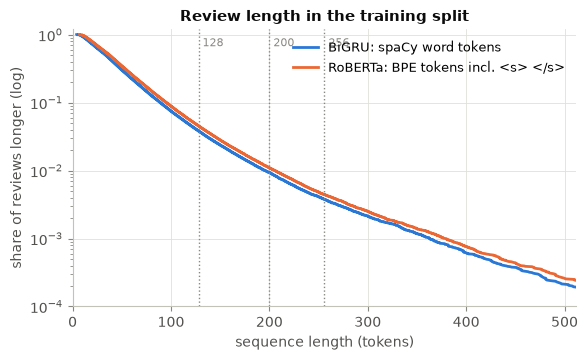

In [14]:
import matplotlib.pyplot as plt
from common import figures_dir
from common.plotting import INK_MUTED, SERIES, set_style

set_style()
fig, ax = plt.subplots(figsize=(6.5, 3.6))
series = [("BiGRU: spaCy word tokens", encoded["train"]["n_tokens"]),
          ("RoBERTa: BPE tokens incl. <s> </s>", rob["train"]["n_tokens"])]
for i, (label, lengths) in enumerate(series):
    x = np.sort(lengths)
    ax.plot(x, 1 - np.arange(1, len(x) + 1) / len(x), color=SERIES[i], label=label)
for cutoff in (128, classic.MAX_LEN, roberta_data.MAX_LEN):
    ax.axvline(cutoff, color=INK_MUTED, linestyle=":", linewidth=1)
    ax.text(cutoff, 0.9, f" {cutoff}", color=INK_MUTED, fontsize=8, va="top")
ax.set_xlim(0, 512)
ax.set_yscale("log")   # the truncated tail is a few percent, invisible on a linear axis
ax.set_ylim(1e-4, 1.2)
ax.set_xlabel("sequence length (tokens)")
ax.set_ylabel("share of reviews longer (log)")
ax.set_title("Review length in the training split")
ax.legend()
if LIMIT is None:   # a subset run must not overwrite the report figure
    fig.savefig(figures_dir(2) / "length_distribution.png", dpi=200, bbox_inches="tight")
plt.show()

## 5. Save what training needs and what the report quotes

The vocabulary and the embedding matrix go to `Question-2/data/classic/` (gitignored) so the BiGRU notebook does not rebuild them. The statistics go to `outputs/results/preprocessing_stats.json`.

In [15]:
import torch
from common import data_dir, results_dir, save_json

if LIMIT is None:   # training must never pick up a vocabulary built from a subset
    classic_dir = data_dir(2) / "classic"
    vocab.save(classic_dir / "vocab.json")
    torch.save(embeddings, classic_dir / "embeddings.pt")

stats = {
    "limit": LIMIT,
    "splits": {split: {"reviews": len(ds), "per_star": label_counts(ds), "title_attached": float(np.mean(ds["title_found"]))}
               for split, ds in reviews.items()},
    "classic": {"min_freq": classic.MIN_FREQ, "max_len": classic.MAX_LEN, "vocab_size": len(vocab),
                "validation_oov_rate": vocab.oov_rate(tokenized["validation"]["tokens"]),
                "glove": {"file": glove_path.name, "dim": classic.GLOVE_DIM, **coverage}, "lengths": classic_lengths},
    "roberta": {"model": roberta_data.MODEL_NAME, "max_len": roberta_data.MAX_LEN, "lengths": roberta_lengths},
}
if LIMIT is None:
    save_json(stats, results_dir(2) / "preprocessing_stats.json")
stats["classic"]["glove"]

{'file': 'glove.6B.300d.txt',
 'dim': 300,
 'vocab_size': 32878,
 'types_with_vector': 28949,
 'type_coverage': 0.8806047332238243,
 'token_coverage': 0.9970924784012201}